In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings('ignore')



In [2]:
from google.colab import files

uploaded = files.upload()

Saving Mall_Customers.csv to Mall_Customers.csv


In [3]:
df = pd.read_csv('Mall_Customers.csv')

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [5]:
df.shape

(200, 5)

In [6]:
df.columns

Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [8]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [9]:
df.isnull().sum()

,0
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Remove duplicate records
df = df.drop_duplicates()

# Remove rows with missing values
df = df.dropna()

# Reset index
df = df.reset_index(drop=True)

print("Cleaned dataset shape:", df.shape)

Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64
Cleaned dataset shape: (200, 5)


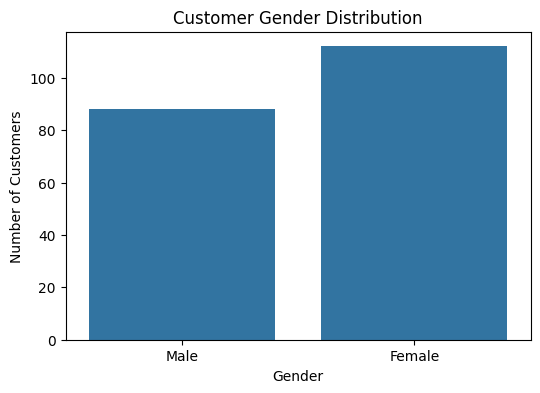

In [13]:
plt.figure(figsize=(6,4))

sns.countplot(data=df, x='Gender')

plt.title('Customer Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')

plt.show()

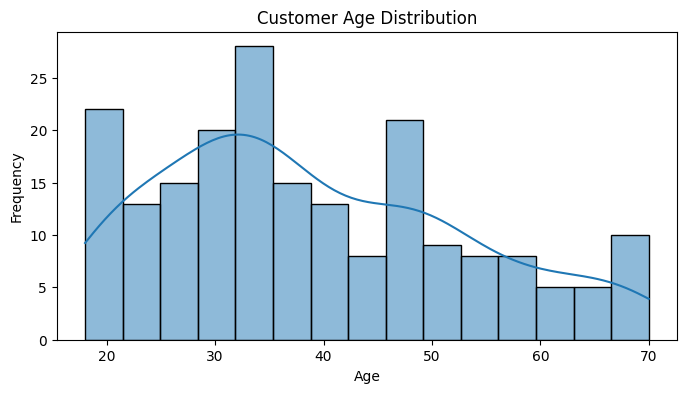

In [14]:
plt.figure(figsize=(8,4))

sns.histplot(data=df, x='Age', bins=15, kde=True)

plt.title('Customer Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')

plt.show()

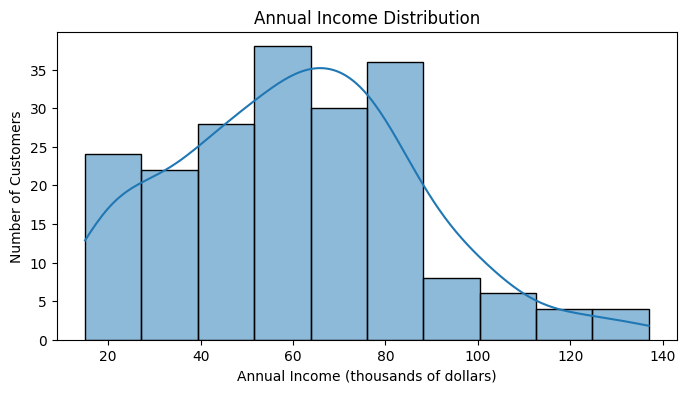

In [15]:
plt.figure(figsize=(8,4))

sns.histplot(data=df, x='Annual Income (k$)', kde=True)

plt.title('Annual Income Distribution')
plt.xlabel('Annual Income (thousands of dollars)')
plt.ylabel('Number of Customers')

plt.show()

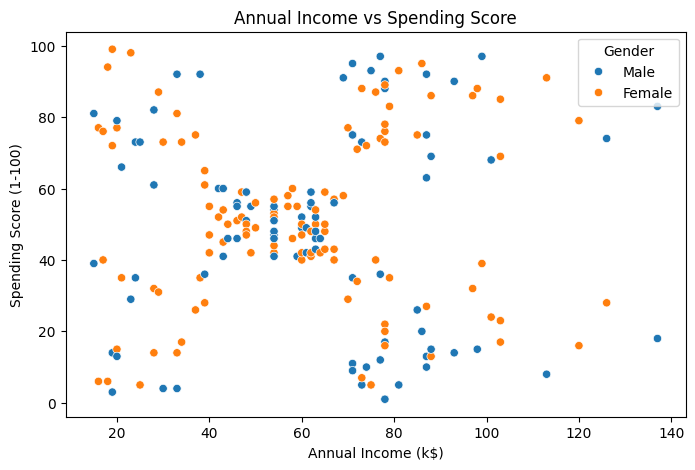

In [17]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Gender'
)

plt.title('Annual Income vs Spending Score')

plt.show()

In [18]:
X = df[['Annual Income (k$)',
        'Spending Score (1-100)']]

X.head()

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [19]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])

[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]


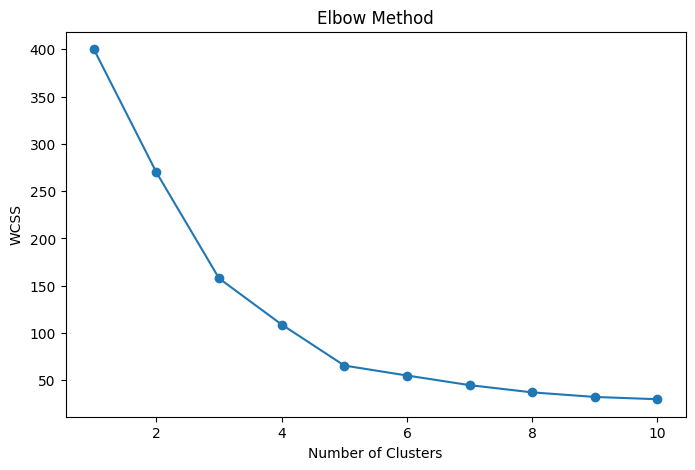

In [20]:
wcss = []

for i in range(1, 11):

    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8,5))

plt.plot(range(1, 11), wcss, marker='o')

plt.title('Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')

plt.show()

In [21]:
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X_scaled)

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4


In [22]:
df['Cluster'].value_counts().sort_index()

,count
Cluster,
0,81
1,39
2,22
3,35
4,23


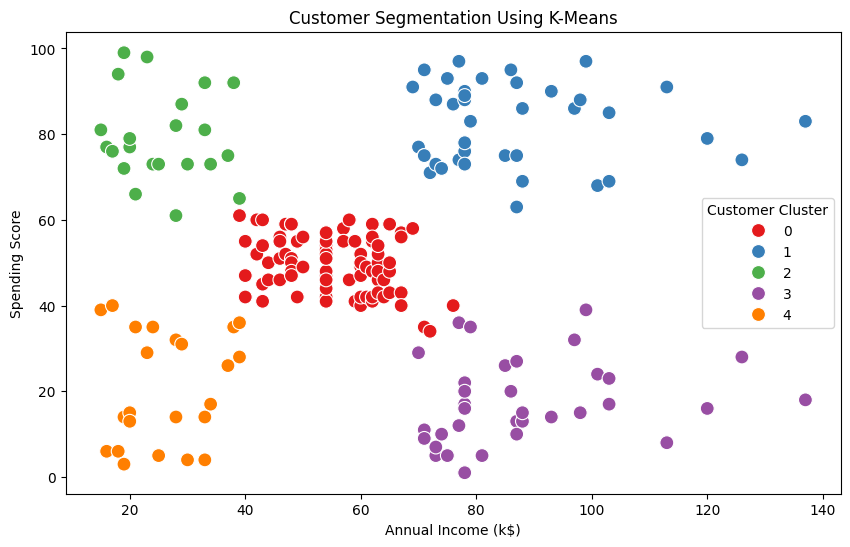

In [23]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster',
    palette='Set1',
    s=100
)

plt.title('Customer Segmentation Using K-Means')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score')

plt.legend(title='Customer Cluster')

plt.show()

In [24]:
cluster_summary = df.groupby('Cluster').agg({
    'Age': 'mean',
    'Annual Income (k$)': 'mean',
    'Spending Score (1-100)': 'mean',
    'CustomerID': 'count'
}).round(2)

cluster_summary.rename(
    columns={'CustomerID': 'Number of Customers'},
    inplace=True
)

cluster_summary

,Age,Annual Income (k$),Spending Score (1-100),Number of Customers
Cluster,,,,
0,42.72,55.30,49.52,81
1,32.69,86.54,82.13,39
2,25.27,25.73,79.36,22
3,41.11,88.20,17.11,35
4,45.22,26.30,20.91,23


In [25]:
score = silhouette_score(X_scaled, df['Cluster'])

print("Silhouette Score:", round(score, 3))

Silhouette Score: 0.555


In [26]:
%%writefile app.py

import streamlit as st
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

st.set_page_config(
    page_title="Customer Analytics",
    page_icon="📊",
    layout="wide"
)

st.title("📊 Mall Customer Segmentation")
st.write("An interactive Business Analytics application")

st.sidebar.header("Upload Customer Dataset")

uploaded_file = st.sidebar.file_uploader(
    "Upload CSV file",
    type=["csv"]
)

if uploaded_file is not None:

    df = pd.read_csv(uploaded_file)

    required_columns = [
        'CustomerID',
        'Genre',
        'Age',
        'Annual Income (k$)',
        'Spending Score (1-100)'
    ]

    if not all(col in df.columns for col in required_columns):
        st.error("Uploaded file does not have the required columns.")

    elif df[required_columns].isnull().any().any():
        st.error("Dataset contains missing values. Please clean it first.")

    else:

        df = df.drop_duplicates().copy()

        st.success("Dataset uploaded successfully!")

        st.subheader("Dataset Overview")

        col1, col2, col3 = st.columns(3)

        col1.metric("Total Customers", len(df))
        col2.metric("Average Age", round(df['Age'].mean(), 1))
        col3.metric(
            "Average Income",
            round(df['Annual Income (k$)'].mean(), 2)
        )

        st.subheader("Customer Dataset")

        st.dataframe(df, use_container_width=True)

        st.subheader("Customer Demographics")

        fig1, ax1 = plt.subplots()

        sns.countplot(data=df, x='Genre', ax=ax1)

        ax1.set_title("Gender Distribution")

        st.pyplot(fig1)
        plt.close(fig1)

        st.subheader("Income Analysis")

        fig2, ax2 = plt.subplots()

        sns.histplot(
            data=df,
            x='Annual Income (k$)',
            kde=True,
            ax=ax2
        )

        ax2.set_title("Annual Income Distribution")

        st.pyplot(fig2)
        plt.close(fig2)

        st.subheader("Customer Segmentation")

        n_clusters = st.sidebar.slider(
            "Select Number of Clusters",
            min_value=2,
            max_value=10,
            value=5
        )

        X = df[
            ['Annual Income (k$)', 'Spending Score (1-100)']
        ]

        scaler = StandardScaler()

        X_scaled = scaler.fit_transform(X)

        kmeans = KMeans(
            n_clusters=n_clusters,
            random_state=42,
            n_init=10
        )

        df['Cluster'] = kmeans.fit_predict(X_scaled)

        score = silhouette_score(X_scaled, df['Cluster'])

        st.metric(
            "Silhouette Score",
            round(score, 3)
        )

        fig3, ax3 = plt.subplots(figsize=(10, 6))

        sns.scatterplot(
            data=df,
            x='Annual Income (k$)',
            y='Spending Score (1-100)',
            hue='Cluster',
            palette='Set1',
            s=100,
            ax=ax3
        )

        ax3.set_title("K-Means Customer Segmentation")

        st.pyplot(fig3)
        plt.close(fig3)

        st.subheader("Customer Segment Summary")

        summary = df.groupby('Cluster').agg({
            'Age': 'mean',
            'Annual Income (k$)': 'mean',
            'Spending Score (1-100)': 'mean',
            'CustomerID': 'count'
        }).round(2)

        summary.rename(
            columns={'CustomerID': 'Customer Count'},
            inplace=True
        )

        st.dataframe(summary, use_container_width=True)

        st.subheader("Business Recommendations")

        st.write(
            "Businesses can use these customer segments "
            "to design targeted marketing campaigns, "
            "improve customer retention and offer "
            "personalised promotions."
        )

        csv = df.to_csv(index=False).encode('utf-8')

        st.download_button(
            "Download Segmented Customer Data",
            data=csv,
            file_name="segmented_customers.csv",
            mime="text/csv"
        )

else:

    st.info("Upload your Mall Customers CSV file to begin.")

Writing app.py


In [27]:
%%writefile requirements.txt

streamlit
pandas
numpy
matplotlib
seaborn
scikit-learn

Writing requirements.txt


In [28]:
import os

print(os.listdir())

['.config', 'app.py', 'Mall_Customers.csv', 'requirements.txt', 'sample_data']


In [29]:
from google.colab import files

files.download('app.py')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:
files.download('requirements.txt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:
%%writefile README.md

# Mall Customer Segmentation Application

## Project Overview

This Business Analytics project analyses mall customer
behaviour using Python and Machine Learning.

## Objective

To identify different customer groups based on annual
income and spending score using K-Means Clustering.

## Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Streamlit

## Machine Learning Technique

K-Means Clustering

## Application Features

- Upload customer dataset
- Customer demographic analysis
- Data visualisation
- Interactive customer segmentation
- Silhouette Score evaluation
- Customer segment summary
- Download segmented data

## How to Run

Install the required libraries:

pip install -r requirements.txt

Run the application:

streamlit run app.py

Writing README.md


In [32]:
files.download('README.md')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>